In [296]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [297]:
data = pd.read_csv('Used_Cars_Homework.csv')

In [298]:
data.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,18479
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,38680
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,40016
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,19668
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,36190


In [299]:
print(f"Размер таблицы: {data.shape[0]} строк, {data.shape[1]} столбцов\n")
print("Типы данных:")
print(data.dtypes)
print("\nКоличество пропусков:")
print(data.isna().sum())

Размер таблицы: 300 строк, 9 столбцов

Типы данных:
age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                object
fuel_type            object
transmission         object
accident_history     object
price_azn             int64
dtype: object

Количество пропусков:
age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64


In [300]:
data.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [301]:
min_price = data['price_azn'].min()
max_price = data['price_azn'].max()
mean_price = data['price_azn'].mean()

print(f"Минимальная стоимость: {min_price} AZN")
print(f"Максимальная стоимость: {max_price} AZN")
print(f"Средняя стоимость: {mean_price:.2f} AZN")

Минимальная стоимость: 3805 AZN
Максимальная стоимость: 51396 AZN
Средняя стоимость: 27806.57 AZN


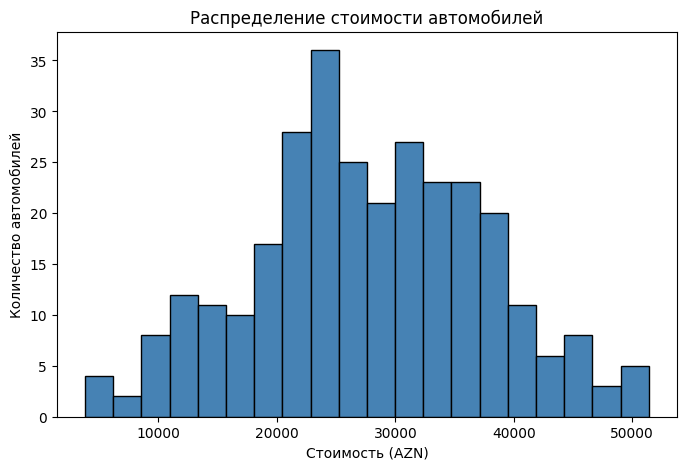

In [302]:
plt.figure(figsize=(8, 5))
plt.hist(data['price_azn'], bins=20, color='steelblue', edgecolor='black')
plt.title('Распределение стоимости автомобилей')
plt.xlabel('Стоимость (AZN)')
plt.ylabel('Количество автомобилей')
plt.show()

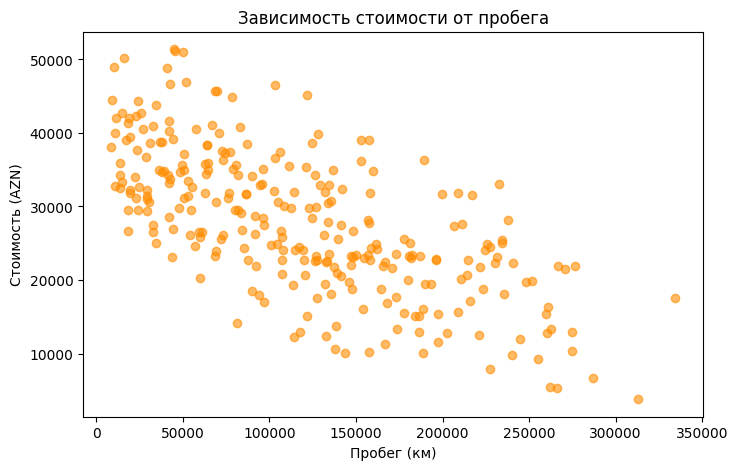

In [303]:
plt.figure(figsize=(8, 5))
plt.scatter(data['mileage_km'], data['price_azn'], alpha=0.6, color='darkorange')
plt.title('Зависимость стоимости от пробега')
plt.xlabel('Пробег (км)')
plt.ylabel('Стоимость (AZN)')
plt.show()

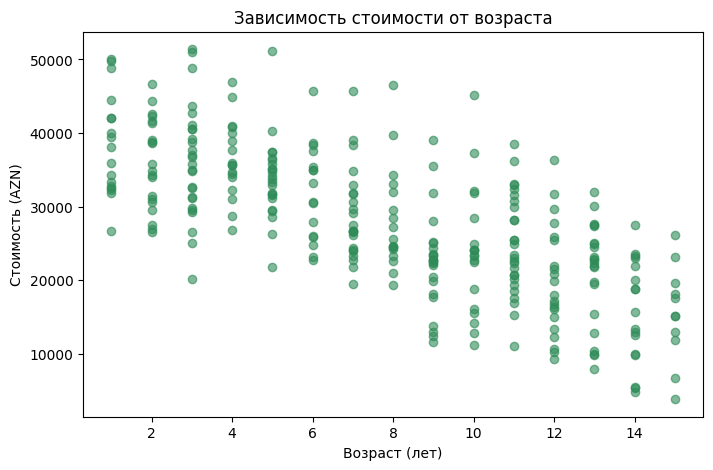

In [304]:
plt.figure(figsize=(8, 5))
plt.scatter(data['age_years'], data['price_azn'], alpha=0.6, color='seagreen')
plt.title('Зависимость стоимости от возраста')
plt.xlabel('Возраст (лет)')
plt.ylabel('Стоимость (AZN)')
plt.show()

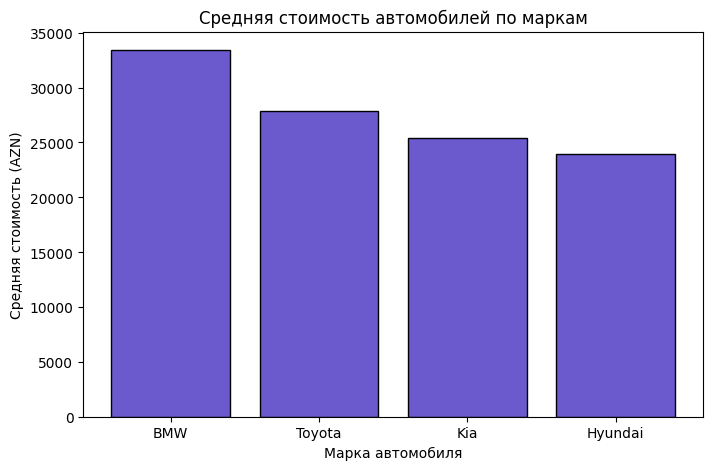

In [305]:
brand_avg_price = data.groupby('brand')['price_azn'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(brand_avg_price.index, brand_avg_price.values, color='slateblue', edgecolor='black')
plt.title('Средняя стоимость автомобилей по маркам')
plt.xlabel('Марка автомобиля')
plt.ylabel('Средняя стоимость (AZN)')
plt.show()

In [306]:
data_fe = data.copy()
data_fe['mileage_per_year'] = data_fe['mileage_km'] / np.where(
    data_fe['age_years'] > 0, data_fe['age_years'], 1
)

target_col = 'price_azn'
X = data_fe.drop(columns=[target_col])
y = data_fe[target_col]



X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Обучающая выборка: {X_train.shape[0]} строк, {X_train.shape[1]} признаков")
print(f"Тестовая выборка: {X_test.shape[0]} строк, {X_test.shape[1]} признаков")

Обучающая выборка: 240 строк, 9 признаков
Тестовая выборка: 60 строк, 9 признаков


In [307]:
numeric_cols = ['age_years', 'mileage_km', 'engine_l', 'power_hp', 'mileage_per_year']
categorical_cols = ['brand', 'fuel_type', 'transmission', 'accident_history']


numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

linreg_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])



In [308]:
X_train_demo = X_train.copy()

codes, uniques = pd.factorize(X_train_demo['brand'])
brand_demo = pd.DataFrame({
    'brand_original': X_train_demo['brand'].values,
    'factorize': codes
}, index=X_train_demo.index)


ohe_demo = OneHotEncoder(sparse_output=False)
ohe_encoded = ohe_demo.fit_transform(X_train_demo[['brand']])
ohe_df = pd.DataFrame(
    ohe_encoded,
    columns=ohe_demo.get_feature_names_out(['brand']),
    index=X_train_demo.index
)

brand_comparison = pd.concat([brand_demo, ohe_df], axis=1)
print("Порядок категорий в factorize:", list(uniques))
brand_comparison.head(8)

Порядок категорий в factorize: ['BMW', 'Toyota', 'Kia', 'Hyundai']


,brand_original,factorize,brand_BMW,brand_Hyundai,brand_Kia,brand_Toyota
232,BMW,0,1.0,0.0,0.0,0.0
59,Toyota,1,0.0,0.0,0.0,1.0
6,Toyota,1,0.0,0.0,0.0,1.0
185,BMW,0,1.0,0.0,0.0,0.0
173,Toyota,1,0.0,0.0,0.0,1.0
30,BMW,0,1.0,0.0,0.0,0.0
22,Toyota,1,0.0,0.0,0.0,1.0
256,Toyota,1,0.0,0.0,0.0,1.0


In [309]:
mms = MinMaxScaler()
std = StandardScaler()

mileage_comparison = pd.DataFrame({
    'mileage_km_original': X_train_demo['mileage_km'].values,
    'MinMaxScaler': mms.fit_transform(X_train_demo[['mileage_km']]).ravel(),
    'StandardScaler': std.fit_transform(X_train_demo[['mileage_km']]).ravel()
}, index=X_train_demo.index)

mileage_comparison.head(8)

,mileage_km_original,MinMaxScaler,StandardScaler
232,52670.0,0.135150,-0.903973
59,81580.0,0.223927,-0.510185
6,124854.0,0.356814,0.079259
185,NaN,NaN,NaN
173,15054.0,0.019638,-1.416348
30,276575.0,0.822722,2.145879
22,193325.0,0.567076,1.011915
256,120461.0,0.343324,0.019421


MinMaxScaler сжимает все значения строго в диапазон от 0 до 1

StandardScaler центрирует данные вокруг 0 Пример: -0.23 , 0.34


In [310]:
linreg_model.fit(X_train, y_train)
y_pred = linreg_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2:   {r2:.4f}")

MAE:  1414.622
MSE:  2886404.320
RMSE: 1698.942
R2:   0.9718


Модель отличная, результаты хорошие R2 почти 1

In [311]:
comparison_df = pd.DataFrame({
    'Реальная стоимость (AZN)': y_test.values,
    'Прогноз модели (AZN)': np.round(y_pred, 2),
    'Абсолютная ошибка (AZN)': np.round(np.abs(y_test.values - y_pred), 2)
}, index=y_test.index)

comparison_df.head(10)

,Реальная стоимость (AZN),Прогноз модели (AZN),Абсолютная ошибка (AZN)
203,34837,32094.81,2742.19
266,34946,33157.90,1788.10
152,32214,31152.66,1061.34
9,36190,35780.66,409.34
233,25000,23648.31,1351.69
226,26522,27360.10,838.10
196,22711,24210.68,1499.68
109,33061,32078.44,982.56
5,18479,19693.81,1214.81
175,25003,23457.43,1545.57


,Количество примеров,Training R²,CV R²,Разница (Train - CV)
0,19,0.9809,0.7726,0.2083
1,43,0.9524,0.9279,0.0245
2,68,0.9486,0.9415,0.0071
3,93,0.9510,0.9385,0.0125
4,117,0.9533,0.9410,0.0124
5,142,0.9555,0.9434,0.0121
6,167,0.9557,0.9457,0.0099
7,192,0.9574,0.9467,0.0106


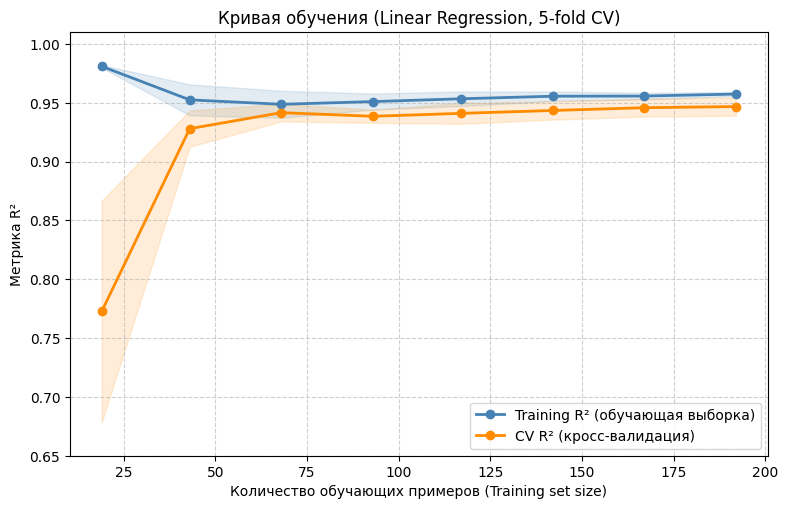

In [312]:
train_sizes, train_scores, test_scores = learning_curve(
    linreg_model,
    X_train,
    y_train,
    cv=5,
    scoring='r2',
    train_sizes=np.linspace(0.1, 1.0, 8),
    shuffle=True,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)


lc_df = pd.DataFrame({
    'Количество примеров': train_sizes,
    'Training R²': np.round(train_mean, 4),
    'CV R²': np.round(test_mean, 4),
    'Разница (Train - CV)': np.round(train_mean - test_mean, 4)
})
display(lc_df)


plt.figure(figsize=(9, 5.5))
plt.plot(train_sizes, train_mean, 'o-', color='steelblue', linewidth=2, label='Training R² (обучающая выборка)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='steelblue')

plt.plot(train_sizes, test_mean, 'o-', color='darkorange', linewidth=2, label='CV R² (кросс-валидация)')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='darkorange')

plt.title('Кривая обучения (Linear Regression, 5-fold CV)')
plt.xlabel('Количество обучающих примеров (Training set size)')
plt.ylabel('Метрика R²')
plt.ylim(0.65, 1.01)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.show()

In [313]:
new_cars = pd.DataFrame({
    'age_years': [5, 10, 3],
    'mileage_km': [75000, 180000, 40000],
    'engine_l': [1.6, 2.0, 2.5],
    'power_hp': [110, 140, 170],
    'brand': ['Toyota', 'Hyundai', 'BMW'],
    'fuel_type': ['petrol', 'diesel', 'petrol'],
    'transmission': ['automatic', 'manual', 'automatic'],
    'accident_history': ['no', 'yes', 'no']
})

new_cars_fe = new_cars.copy()
new_cars_fe['mileage_per_year'] = new_cars_fe['mileage_km'] / np.where(
    new_cars_fe['age_years'] > 0, new_cars_fe['age_years'], 1
)

predicted_prices = linreg_model.predict(new_cars_fe)


predictions_table = new_cars.copy()
predictions_table['mileage_per_year'] = new_cars_fe['mileage_per_year'].round(1)
predictions_table['Прогноз стоимости (AZN)'] = np.round(predicted_prices, 2)

display(predictions_table)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,mileage_per_year,Прогноз стоимости (AZN)
0,5,75000,1.6,110,Toyota,petrol,automatic,no,15000.0,31170.63
1,10,180000,2.0,140,Hyundai,diesel,manual,yes,18000.0,15912.01
2,3,40000,2.5,170,BMW,petrol,automatic,no,13333.3,48791.50
